# Задание 2

In [1]:
import pandas as pd
import numpy as np
import scipy.stats as st
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score

## Загружаем данные

In [2]:
# Читаем данные сотрудников
hr = pd.read_csv('HR.csv')
hr.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [5]:
# Проверяем размер, типы и пропуски
hr.shape

(14999, 10)

In [6]:
hr.isna().sum()

satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
department               0
salary                   0
dtype: int64

In [7]:
hr.dtypes

satisfaction_level       float64
last_evaluation          float64
number_project             int64
average_montly_hours       int64
time_spend_company         int64
Work_accident              int64
left                       int64
promotion_last_5years      int64
department                   str
salary                       str
dtype: object

In [8]:
# есть 3 008 полных повторов строк
hr.duplicated().sum()

np.int64(3008)

In [9]:
# Считаем статистики числовых полей
hr.describe()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612834,0.716102,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268
std,0.248631,0.171169,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


In [10]:
# Находим моды категориальных полей
hr['department'].mode()

0    sales
Name: department, dtype: str

In [11]:
hr['salary'].mode()

0    low
Name: salary, dtype: str

## 3. Корреляция количественных переменных

Возьмём пять количественных признаков. `Work_accident`, `left` и `promotion_last_5years` — бинарные категории, поэтому в эту матрицу их не включаем. Корреляцию Пирсона считаем по исходным строкам, без предварительного усреднения.

Силу связи сравниваем по модулю коэффициента: значение около нуля означает слабую линейную связь, около −1 или 1 — сильную.

In [14]:
# Считаем корреляции количественных признаков
quantitative_columns = [
    'satisfaction_level',
    'last_evaluation',
    'number_project',
    'average_montly_hours',
    'time_spend_company'
]

correlation_matrix = hr[quantitative_columns].corr()
correlation_matrix.round(3)

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company
satisfaction_level,1.000,0.105,-0.143,-0.020,-0.101
last_evaluation,0.105,1.000,0.349,0.340,0.132
number_project,-0.143,0.349,1.000,0.417,0.197
average_montly_hours,-0.020,0.340,0.417,1.000,0.128
time_spend_company,-0.101,0.132,0.197,0.128,1.000


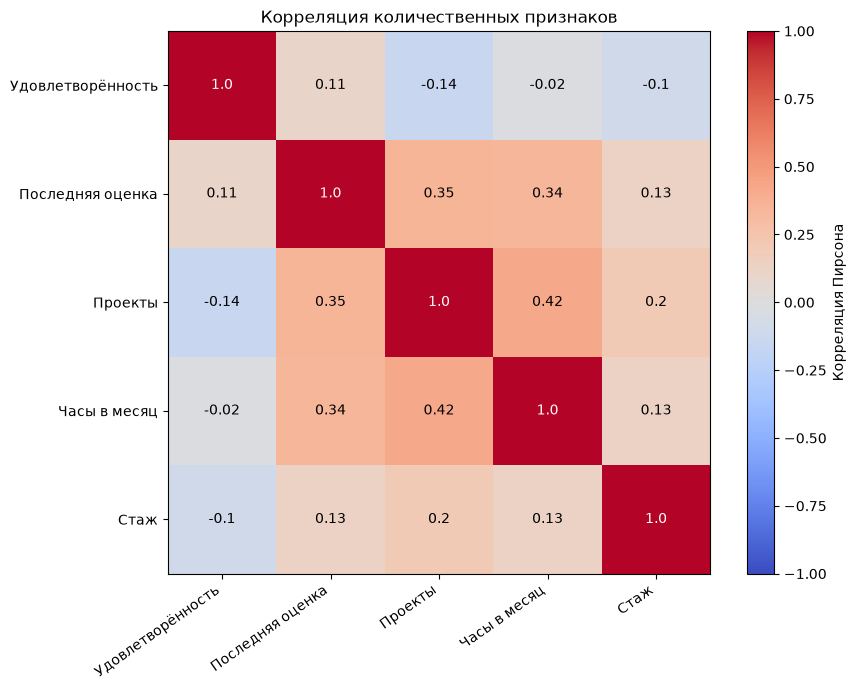

In [15]:
# Рисуем матрицу корреляций
labels = ['Удовлетворённость', 'Последняя оценка', 'Проекты', 'Часы в месяц', 'Стаж']
plt.figure(figsize=(9, 7))
plt.imshow(correlation_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Корреляция Пирсона')
plt.xticks(range(len(labels)), labels, rotation=35, ha='right')
plt.yticks(range(len(labels)), labels)

for i in range(len(labels)):
    for j in range(len(labels)):
        value = correlation_matrix.iloc[i, j]
        color = 'white' if abs(value) > 0.6 else 'black'
        plt.text(j, i, round(value, 2), ha='center', va='center', color=color)

plt.title('Корреляция количественных признаков')
plt.tight_layout()
plt.show()

In [32]:
# Сравниваем уникальные пары признаков
pairs = []

for i in range(len(quantitative_columns)):
    for j in range(i + 1, len(quantitative_columns)):
        value = correlation_matrix.iloc[i, j]
        pairs.append([quantitative_columns[i], quantitative_columns[j], value, abs(value)])

correlation_pairs = pd.DataFrame(pairs, columns=['Признак 1', 'Признак 2', 'Корреляция', 'Модуль'])
correlation_pairs = correlation_pairs.sort_values('Модуль', ascending=False)

print('Самая сильная связь:')
print(correlation_pairs.head(2))
print('\nСамая слабая связь:')
print(correlation_pairs.tail(2))

Самая сильная связь:
         Признак 1             Признак 2  Корреляция    Модуль
7   number_project  average_montly_hours    0.417211  0.417211
4  last_evaluation        number_project    0.349333  0.349333

Самая слабая связь:
            Признак 1             Признак 2  Корреляция    Модуль
3  satisfaction_level    time_spend_company   -0.100866  0.100866
2  satisfaction_level  average_montly_hours   -0.020048  0.020048


In [30]:
# Самая скоррелированная пара: количество проектов и часы в месяц, больше проектов обычно связано с большим количеством рабочих часов

# Наименее скоррелированная пара: удовлетворённость и часы в месяц

<Axes: xlabel='number_project', ylabel='average_montly_hours'>

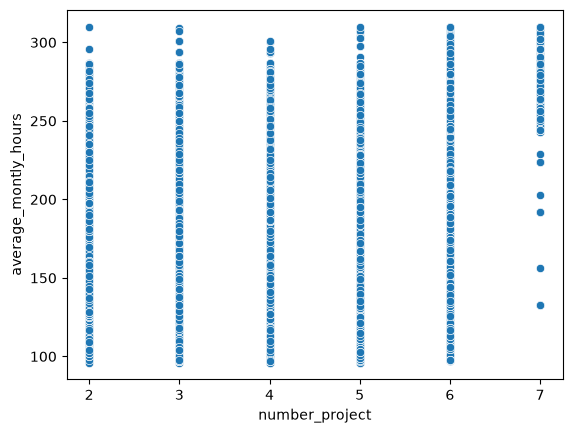

In [19]:
# связь нелинейная
sns.scatterplot(data = hr, x = 'number_project', y = 'average_montly_hours')

<Axes: xlabel='satisfaction_level', ylabel='average_montly_hours'>

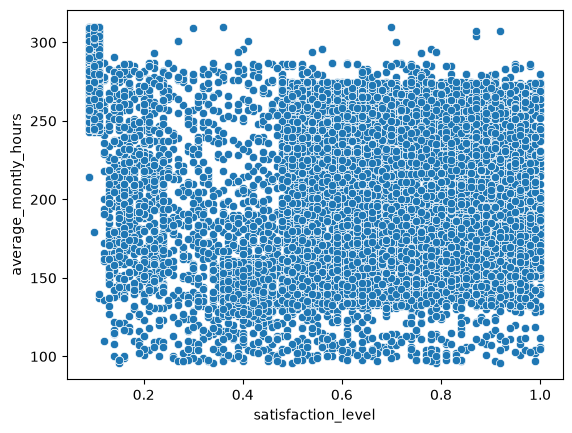

In [20]:
sns.scatterplot(data = hr, x = 'satisfaction_level', y = 'average_montly_hours')

## Число сотрудников по департаментам

In [21]:
# Считаем сотрудников в каждом отделе
department_counts = hr['department'].value_counts()
department_counts

department
sales          4140
technical      2720
support        2229
IT             1227
product_mng     902
marketing       858
RandD           787
accounting      767
hr              739
management      630
Name: count, dtype: int64

## Распределение по зарплатам

<Axes: xlabel='salary', ylabel='Count'>

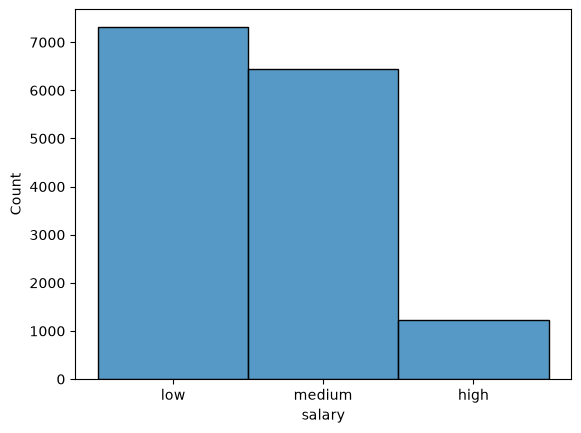

In [23]:
sns.histplot(data = hr, x = 'salary')

## Зарплаты в каждом департаменте

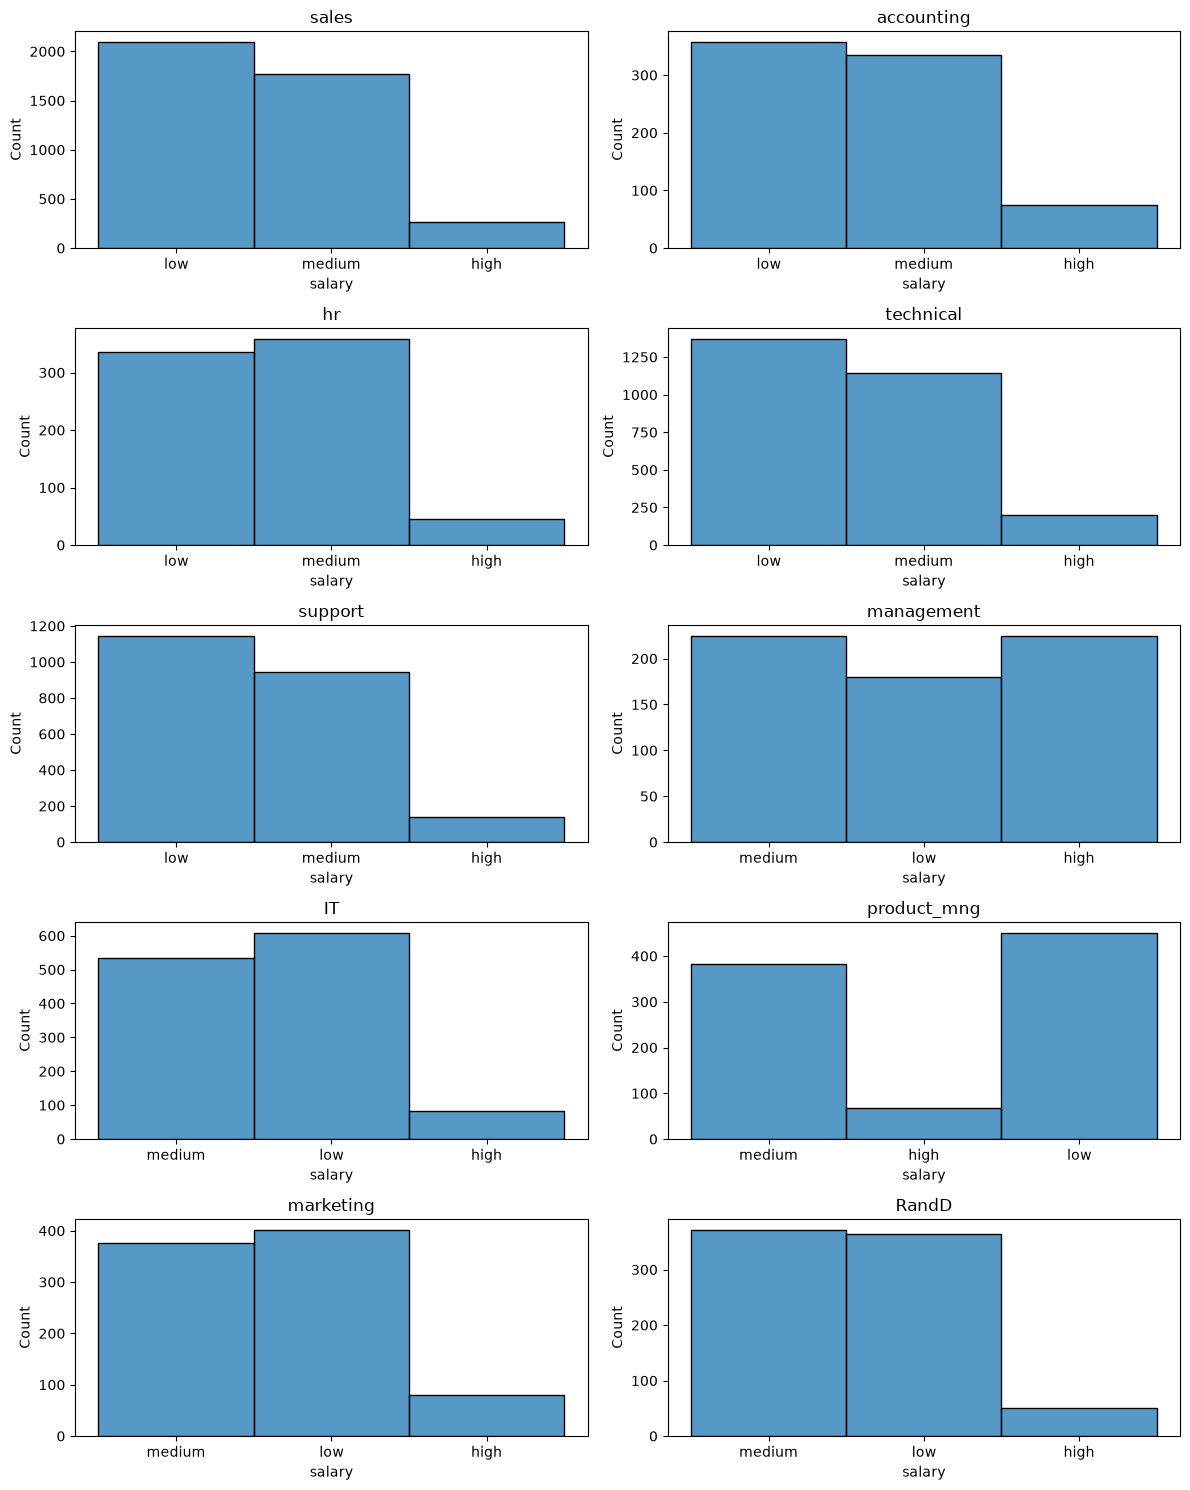

In [29]:
# Показываем зарплаты по отделам на одном полотне
plt.figure(figsize=(12, 15))

for i, department in enumerate(hr['department'].unique()):
    department_data = hr[hr['department'] == department]

    plt.subplot(5, 2, i + 1)
    sns.histplot(data=department_data, x='salary')
    plt.title(department)

plt.tight_layout()
plt.show()

## Проверяем гипотезу о рабочих часах

In [ ]:
# Проверка на выбросы

In [33]:
high_hours = hr[hr['salary'] == 'high']

<Axes: xlabel='salary', ylabel='average_montly_hours'>

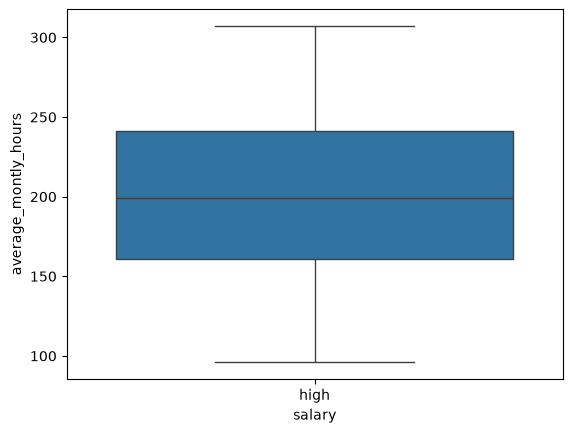

In [34]:
sns.boxplot(data = high_hours, x = 'salary', y = 'average_montly_hours')

In [35]:
low_hours = hr[hr['salary'] == 'low']

<Axes: xlabel='salary', ylabel='average_montly_hours'>

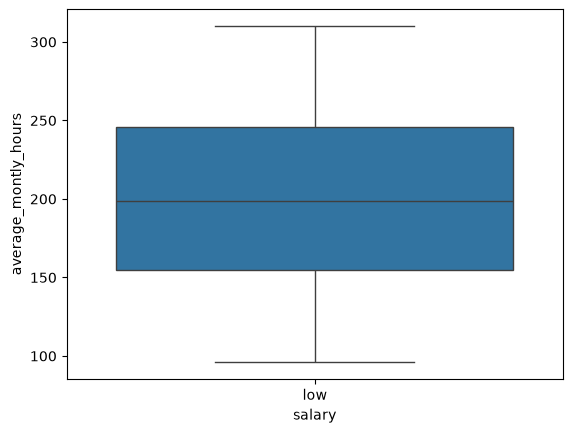

In [36]:
sns.boxplot(data = low_hours, x = 'salary', y = 'average_montly_hours')

In [39]:
print('Высокий оклад, сотрудников:', len(high_hours))
print('Низкий оклад, сотрудников:', len(low_hours))
print('Средние часы при высоком окладе:', round(high_hours['average_montly_hours'].mean(), 2))
print('Средние часы при низком окладе:', round(low_hours['average_montly_hours'].mean(), 2))
print('Разница средних:', round(high_hours['average_montly_hours'].mean() - low_hours['average_montly_hours'].mean(), 2))

Высокий оклад, сотрудников: 1237
Низкий оклад, сотрудников: 7316
Средние часы при высоком окладе: 199.87
Средние часы при низком окладе: 201.0
Разница средних: -1.13


In [ ]:
# Cравниваем среднее количество часов в месяц на респондента, обычная поюзерная метрика среднего, тест - высокооплачиваемые, контроль - низкооплачиваемые.
# H0: среднее число часов у сотрудников с высоким окладом не больше, чем у сотрудников с низким окладом.
# H1: среднее число часов у сотрудников с высоким окладом больше.
# Статкритерий: односторонний t-тест Уэлча (односторонний поскольку гипотеза звучит как "сотрудники с высоким окладом проводят на работе больше времени, чем сотрудники с низким окладом")
# Уровень значимости: 0,05
# Допущения:
#     - Равенство дисперсий не требуется по Уэлчу, мощность при этом почти не страдает
#     - Нормальность распределения выборочных средних гарантируется по ЦПТ для выборок > 30 наблюдений
#     - Выбросы по межквартильному подходу отсутствуют
#     - Независимость данных предполагаем, 1 строка - 1 уникальный респондент

In [41]:
# Проверяем, больше ли часов при высоком окладе
alpha = 0.05
t_statistic, p_value = st.ttest_ind(high_hours['average_montly_hours'], low_hours['average_montly_hours'], equal_var=False, alternative='greater')

print('t-статистика:', t_statistic)
print('p-value:', p_value)

if p_value < alpha:
    print('Отвергаем H0: данные поддерживают гипотезу о большем числе часов')
else:
    print('Не отвергаем H1: гипотеза о большем числе часов не подтверждается')

t-статистика: -0.7624331665385475
p-value: 0.7770477228871057
Не отвергаем H1: гипотеза о большем числе часов не подтверждается


## Сравниваем уволившихся и оставшихся

In [42]:
# Считаем показатели для двух групп
# У бинарного столбца `promotion_last_5years` среднее равно доле сотрудников с повышением. Переведём её в проценты.
left_summary = hr.groupby('left')[['promotion_last_5years', 'satisfaction_level', 'number_project']].mean()
left_summary['promotion_last_5years'] = left_summary['promotion_last_5years'] * 100
left_summary.columns = ['Доля повышенных, %', 'Средняя удовлетворённость', 'Среднее число проектов']
left_summary.index = ['Не уволились', 'Уволились']
left_summary.round(3)

,"Доля повышенных, %",Средняя удовлетворённость,Среднее число проектов
Не уволились,2.625,0.667,3.787
Уволились,0.532,0.440,3.856


## Разделяем данные

In [44]:
# Из признаков исключаем `left`, `department` и `salary`. Остальные семь признаков используем для модели.
# На обучение выделим 80% строк, на тест — 20%. `stratify=y` сохраняет примерно одинаковую долю классов. `random_state=42` позволяет повторить разбиение.
X = hr.drop(columns=['left', 'department', 'salary'])
y = hr['left']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print('Признаки:', X.columns.tolist())
print('Обучающая выборка:', X_train.shape)
print('Тестовая выборка:', X_test.shape)

Признаки: ['satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours', 'time_spend_company', 'Work_accident', 'promotion_last_5years']
Обучающая выборка: (11999, 7)
Тестовая выборка: (3000, 7)


##  Обучаем LDA

In [46]:
# Обучаем модель и делаем прогноз
# Используем LDA как классификатор: модель предсказывает 0 или 1. Обучаем её только на обучающей выборке. 

lda = LinearDiscriminantAnalysis()
lda.fit(X_train, y_train)
y_pred = lda.predict(X_test)

## Оцениваем accuracy

In [47]:
# Сравниваем точность модели с простым прогнозом
# Для сравнения посчитаем accuracy простого прогноза: всем сотрудникам присвоить самый частый класс обучающей выборки.
accuracy = accuracy_score(y_test, y_pred)
majority_class = y_train.mode().iloc[0]
baseline_pred = np.full(len(y_test), majority_class)
baseline_accuracy = accuracy_score(y_test, baseline_pred)

print('Accuracy LDA:', round(accuracy, 4))
print('Правильные прогнозы LDA, %:', round(accuracy * 100, 2))
print('Accuracy простого прогноза:', round(baseline_accuracy, 4))
print('Разница, п.п.:', round((accuracy - baseline_accuracy) * 100, 2))

Accuracy LDA: 0.7667
Правильные прогнозы LDA, %: 76.67
Accuracy простого прогноза: 0.762
Разница, п.п.: 0.47


In [ ]:
# LDA правильно предсказала статус 76,67% сотрудников тестовой выборки. 
# Простой прогноз "не уволился" дал 76,20%. 
# Преимущество модели составляет всего 0,47 п.п, поэтому её результат по accuracy близок к простому прогнозу.